# Amazon Prime TV Shows and Movies — EDA

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab

**Files:** `titles.csv` and `credits.csv`

## 1. Business Context

Streaming platforms have a large amount of content. Data analysis can help us understand:

- What is the mix of Movies and TV Shows?
- Which genres occur most frequently?
- How does the content pattern change across release years?
- Is there a relationship between IMDb and TMDB ratings?
- Which actors and directors are frequently credited?
- Which production countries are represented in the content?


## 2. Problem Statement

Perform Exploratory Data Analysis (EDA) on the available Amazon Prime Video Movies and TV Shows to identify meaningful business insights from content-library patterns, distributions, ratings, runtime, genres, countries, and credits.

## 3. Import Libraries

We will now import the Python libraries required for the analysis.

- **Pandas:** for loading, cleaning, and analyzing data
- **NumPy:** for numerical operations
- **Matplotlib / Seaborn:** for charts and visualizations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


### Output
`Libraries imported successfully!`

This means the required libraries were loaded successfully.

## 4. Load the Two CSV Files

We will now load `titles.csv` and `credits.csv`.

> If the files are stored in a Google Drive folder in Colab, change the paths below according to your folder location.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

titles_path = '/content/drive/MyDrive/Amazon_Prime_EDA/titles.csv'
credits_path = '/content/drive/MyDrive/Amazon_Prime_EDA/credits.csv'

titles = pd.read_csv(titles_path)
credits = pd.read_csv(credits_path)

print("Titles shape:", titles.shape)
print("Credits shape:", credits.shape)

Mounted at /content/drive
Titles shape: (9871, 15)
Credits shape: (124235, 5)


### Output from the current notebook

- `titles.csv` → **9,871 rows × 15 columns**
- `credits.csv` → **124,235 rows × 5 columns**

The shape format is `(rows, columns)`.

## 5. Basic Data Inspection

We will first examine the first few rows, columns, and data types.

The purpose of this step is to understand the dataset. We are not performing any cleaning yet.

In [3]:
display(titles.head())
display(credits.head())



,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


,person_id,id,name,character,role
0,59401,ts20945,Joe Besser,Joe,ACTOR
1,31460,ts20945,Moe Howard,Moe,ACTOR
2,31461,ts20945,Larry Fine,Larry,ACTOR
3,21174,tm19248,Buster Keaton,Johnny Gray,ACTOR
4,28713,tm19248,Marion Mack,Annabelle Lee,ACTOR


In [4]:
print("Titles columns:")
print(titles.columns.tolist())

print("\nCredits columns:")
print(credits.columns.tolist())

Titles columns:
['id', 'title', 'type', 'description', 'release_year', 'age_certification', 'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']

Credits columns:
['person_id', 'id', 'name', 'character', 'role']


In [5]:
print("\nTitles info:")
titles.info()


Titles info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   object 
 1   title                 9871 non-null   object 
 2   type                  9871 non-null   object 
 3   description           9752 non-null   object 
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   object 
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   object 
 8   production_countries  9871 non-null   object 
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   object 
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: floa

In [ ]:
print("\nCredits info:")
credits.info()


Credits info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124235 entries, 0 to 124234
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   person_id  124235 non-null  int64 
 1   id         124235 non-null  object
 2   name       124235 non-null  object
 3   character  107948 non-null  object
 4   role       124235 non-null  object
dtypes: int64(1), object(4)
memory usage: 4.7+ MB


## 6. Data Dictionary

A data dictionary gives us a basic understanding of each column.

Examples:
- `title` → name of the movie/show
- `type` → Movie or TV Show
- `release_year` → release year
- `runtime` → duration
- `genres` → content categories
- `imdb_score` → IMDb rating
- `tmdb_score` → TMDB rating

In [ ]:
data_dictionary = pd.DataFrame({
    "Column": titles.columns,
    "Data Type": titles.dtypes.astype(str).values,
    "Missing Values": titles.isna().sum().values,
    "Unique Values": titles.nunique().values
})

display(data_dictionary)

,Column,Data Type,Missing Values,Unique Values
0,id,object,0,9868
1,title,object,0,9737
2,type,object,0,2
3,description,object,119,9734
4,release_year,int64,0,110
5,age_certification,object,6487,11
6,runtime,int64,0,207
7,genres,object,0,2028
8,production_countries,object,0,497
9,seasons,float64,8514,32


## 7. Clean Column Names and Data Types

We will make the column names consistent and convert important numeric columns to numeric data types.

`errors='coerce'` means that if a value cannot be converted to a number, it will be converted to `NaN`.

In [ ]:
titles.columns = titles.columns.str.strip().str.lower()
credits.columns = credits.columns.str.strip().str.lower()

numeric_cols = [
    'release_year', 'runtime', 'seasons',
    'imdb_score', 'imdb_votes',
    'tmdb_popularity', 'tmdb_score'
]

for col in numeric_cols:
    if col in titles.columns:
        titles[col] = pd.to_numeric(titles[col], errors='coerce')

print(titles.dtypes)

id                       object
title                    object
type                     object
description              object
release_year              int64
age_certification        object
runtime                   int64
genres                   object
production_countries     object
seasons                 float64
imdb_id                  object
imdb_score              float64
imdb_votes              float64
tmdb_popularity         float64
tmdb_score              float64
dtype: object


## 8. Missing Values

A missing value means that information is not available in a particular cell.

We will not blindly delete missing values.

Examples:
- `seasons` may be missing for Movies because seasons are related to TV Shows.
- A missing IMDb score should not be replaced with `0`.
- Displaying missing certification values as `Unknown` can make the analysis easier to interpret.

In [6]:
missing = pd.DataFrame({
    "Missing Count": titles.isna().sum(),
    "Missing %": (titles.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)

display(missing[missing["Missing Count"] > 0])

,Missing Count,Missing %
seasons,8514,86.25
age_certification,6487,65.72
tmdb_score,2082,21.09
imdb_votes,1031,10.44
imdb_score,1021,10.34
imdb_id,667,6.76
tmdb_popularity,547,5.54
description,119,1.21


### Important missing values

- `seasons` → **8,514**
- `age_certification` → **6,487**
- `tmdb_score` → **2,082**
- `imdb_votes` → **1,031**
- `imdb_score` → **1,021**
- `imdb_id` → **667**

**Decision:** Do not delete these values without a valid reason.

## 9. Duplicate Check

Duplicate rows can create data-quality problems.

We will:
1. Check for complete duplicate rows.
2. Check for duplicate `id` values.

The first step is to identify duplicates; we will not automatically delete them.

In [ ]:
print("Duplicate rows in titles:", titles.duplicated().sum())
print("Duplicate rows in credits:", credits.duplicated().sum())
print("Duplicate title IDs:", titles["id"].duplicated().sum())

Duplicate rows in titles: 3
Duplicate rows in credits: 56
Duplicate title IDs: 3


### Result

- Duplicate rows in Titles → **3**
- Duplicate rows in Credits → **56**
- Duplicate title IDs → **3**


Here duplicates were identified and that the decision to remove them should depend on the business/data context. Avoid simply applying `drop_duplicates()` without explaining the reason.

## 10. Descriptive Statistics

We will now look at an overall summary of the numerical columns.

- **Mean** = average
- **Median** = middle value
- **Min/Max** = smallest/largest value
- **Std** = spread/variation

In [ ]:
summary = titles[
    ['runtime', 'imdb_score', 'imdb_votes',
     'tmdb_popularity', 'tmdb_score']
].describe().T

display(summary)

,count,mean,std,min,25%,50%,75%,max
runtime,9871.0,85.973052,33.512466,1.000000,65.000,89.000,102.000,549.000
imdb_score,8850.0,5.976395,1.343842,1.100000,5.100,6.100,6.900,9.900
imdb_votes,8840.0,8533.614253,45920.151905,5.000000,117.000,462.500,2236.250,1133692.000
tmdb_popularity,9324.0,6.910204,30.004098,0.000011,1.232,2.536,5.634,1437.906
tmdb_score,7789.0,5.984247,1.517986,0.800000,5.100,6.000,6.900,10.000


### Important values from the current notebook

- Runtime mean ≈ **85.97 minutes**
- Runtime median = **89 minutes**
- IMDb mean ≈ **5.98**
- IMDb median = **6.1**
- TMDB mean ≈ **5.98**
- TMDB median = **6.0**

Comparing the mean and median gives us a basic idea of the distribution.

## 11. Outlier Analysis — Runtime

An outlier is a value that is unusually high or low compared with the other observations.

Example: 90, 95, 100, 105, 500 → `500` is an unusual value.

We will use the **IQR method**:

- Q1 = 25th percentile
- Q3 = 75th percentile
- IQR = Q3 - Q1
- Lower bound = Q1 - 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR

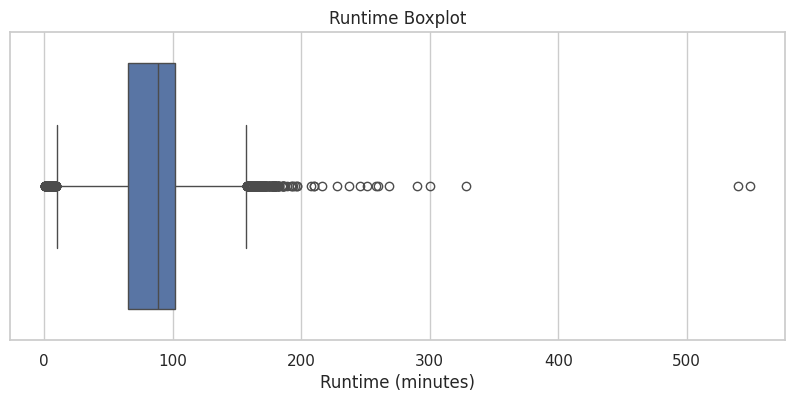

Q1: 65.0
Q3: 102.0
IQR: 37.0
Lower Bound: 9.5
Upper Bound: 157.5
Potential Runtime Outliers: 275


,title,type,runtime
2,The Best Years of Our Lives,MOVIE,171
10,Intolerance: Love's Struggle Throughout the Ages,MOVIE,197
87,The Green Hornet,MOVIE,258
148,Tarzan the Fearless,MOVIE,228
292,Sabapathy,MOVIE,158
807,En Manaivi,MOVIE,170
848,Vazhkai,MOVIE,170
904,Custer's Last Stand,MOVIE,328
966,Jesus of Nazareth,MOVIE,237
974,"It's a Mad, Mad, Mad, Mad World",MOVIE,163


In [ ]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=titles["runtime"])
plt.title("Runtime Boxplot")
plt.xlabel("Runtime (minutes)")
plt.show()

Q1 = titles["runtime"].quantile(0.25)
Q3 = titles["runtime"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

runtime_outliers = titles[
    (titles["runtime"] < lower_bound) |
    (titles["runtime"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Potential Runtime Outliers:", len(runtime_outliers))

display(runtime_outliers[["title", "type", "runtime"]].head(10))

### Current notebook result

**275 potential runtime outliers** were identified.

### Important
An outlier does not automatically mean that the data is incorrect. Long movies or special content can genuinely exist.

Therefore, this project **identifies** outliers rather than blindly deleting them.

# 12. Hypotheses

Before starting EDA, it is useful to define a few questions/hypotheses:

1. There may be more Movies than TV Shows.
2. Drama and Comedy may be frequently occurring genres.
3. The number of titles may change across release years.
4. IMDb and TMDB scores may have a positive relationship.

# 13. Univariate Analysis — Movies vs TV Shows

**Business Question:** Are there more Movies or TV Shows in the dataset?

Here we will look at both the count and percentage.

,Count
type,
MOVIE,8514
SHOW,1357


,Percentage
type,
MOVIE,86.25
SHOW,13.75


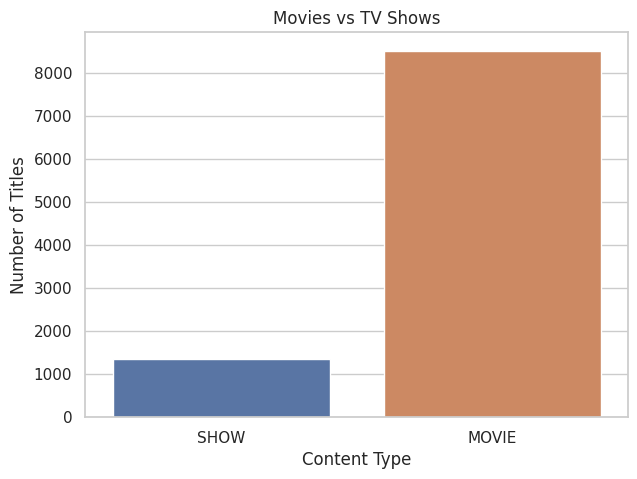

In [ ]:
type_count = titles["type"].value_counts()
type_percentage = (titles["type"].value_counts(normalize=True) * 100).round(2)

display(type_count.to_frame("Count"))
display(type_percentage.to_frame("Percentage"))

plt.figure(figsize=(7, 5))
sns.countplot(data=titles, x="type", hue="type", legend=False)
plt.title("Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

### Current notebook result

- Movies = **8,514 (86.25%)**
- TV Shows = **1,357 (13.75%)**

### Insight
The dataset is strongly **movie-heavy**.

### Business meaning
This information is useful for understanding the content mix. If the platform wants to expand TV content, the current mix can be used as a benchmark.

# 14. Genre Analysis

`genres` represents the category of a movie/show, such as Drama, Comedy, Action, or Romance.

A single title can belong to multiple genres.

Example:
`["Action", "Drama", "Thriller"]`

Therefore, we need to explode the list into separate rows.

In [ ]:
genre_data = titles[["id", "title", "genres"]].dropna(subset=["genres"]).copy()

def parse_list(value):
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []

genre_data["genres"] = genre_data["genres"].apply(parse_list)
genre_data = genre_data.explode("genres")

genre_data["genres"] = genre_data["genres"].astype(str).str.strip()
genre_data = genre_data[genre_data["genres"].ne("")]

genre_count = genre_data["genres"].value_counts()

display(genre_count.head(10).to_frame("Title Count"))

,Title Count
genres,
drama,4764
comedy,2987
thriller,2119
action,1820
romance,1752
crime,1251
documentation,1096
horror,1065
family,751


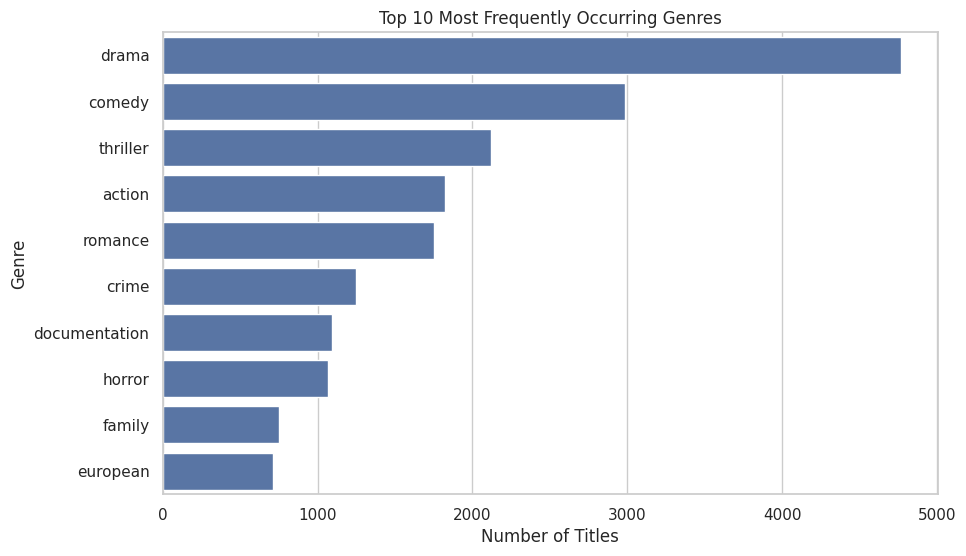

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x=genre_count.head(10).values,
    y=genre_count.head(10).index
)
plt.title("Top 10 Most Frequently Occurring Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.show()

### Current notebook result

Top genres included:

- Drama → **4,764**
- Comedy → **2,987**
- Thriller → **2,119**
- Action → **1,820**
- Romance → **1,752**

### Improvement over the old notebook
The old notebook repeated genre parsing across two cells and previously used `eval()`. The new version uses **`ast.literal_eval()`**, which is a safer approach.

In the report, use **"most frequently occurring"** instead of **"most popular."**

# 15. Release Year Trend

**Business Question:** How does the number of titles in the dataset change over time?

A line chart is useful for observing trends.

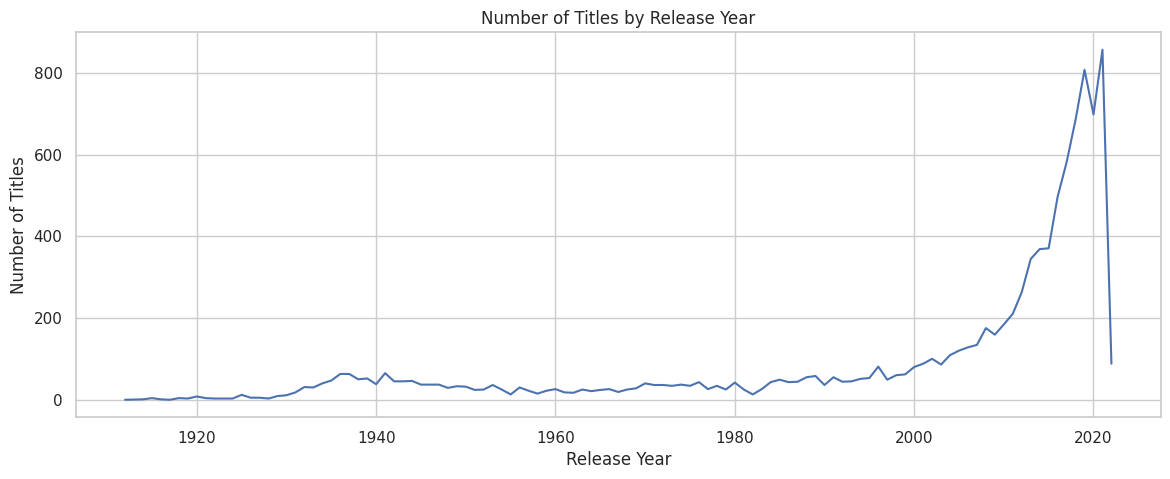

,Title Count
release_year,
2013,345
2014,369
2015,371
2016,497
2017,581
2018,685
2019,807
2020,698
2021,856


In [ ]:
yearly_titles = (
    titles["release_year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(14, 5))
sns.lineplot(x=yearly_titles.index, y=yearly_titles.values)
plt.title("Number of Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

display(yearly_titles.tail(10).to_frame("Title Count"))

### Current notebook observation

There were **856 titles** in 2021, which was the highest among the recent years shown in the notebook.

**Important caution:** The count for 2022 is only **89**. Therefore, we should not conclude that Amazon suddenly reduced content production/release in 2022. Recent-year coverage in the dataset may be incomplete.

# 16. IMDb and TMDB Ratings

We will now compare the two rating systems.

We will:
1. Examine their distributions.
2. Create a scatter plot.
3. Calculate the correlation.

**Correlation range:** -1 to +1.

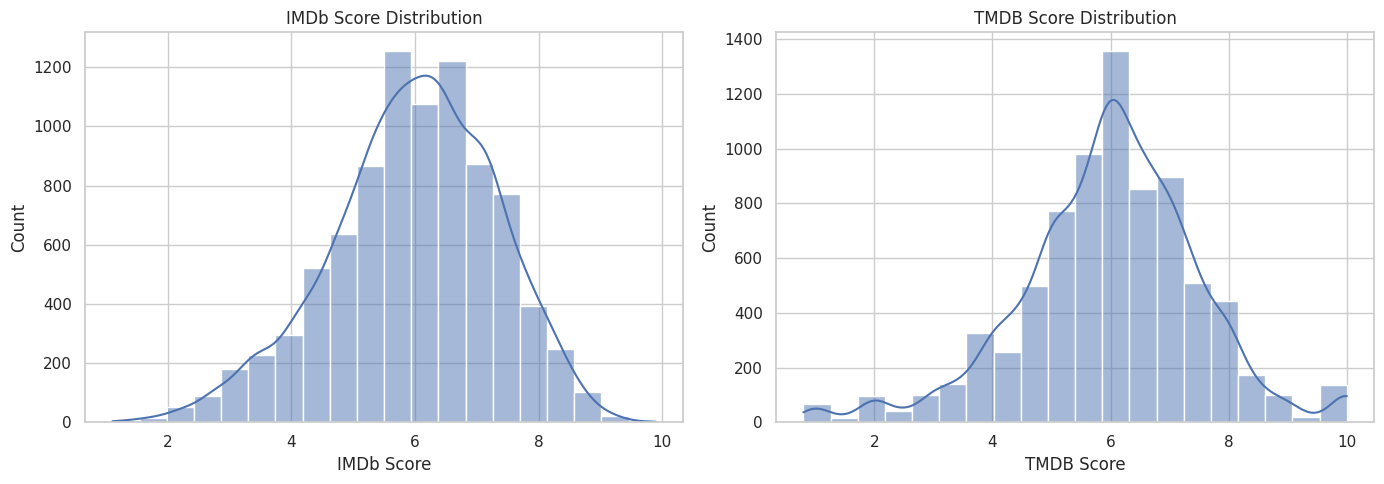

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(titles["imdb_score"].dropna(), bins=20, kde=True, ax=axes[0])
axes[0].set_title("IMDb Score Distribution")
axes[0].set_xlabel("IMDb Score")

sns.histplot(titles["tmdb_score"].dropna(), bins=20, kde=True, ax=axes[1])
axes[1].set_title("TMDB Score Distribution")
axes[1].set_xlabel("TMDB Score")

plt.tight_layout()
plt.show()

IMDb-TMDB correlation: 0.581


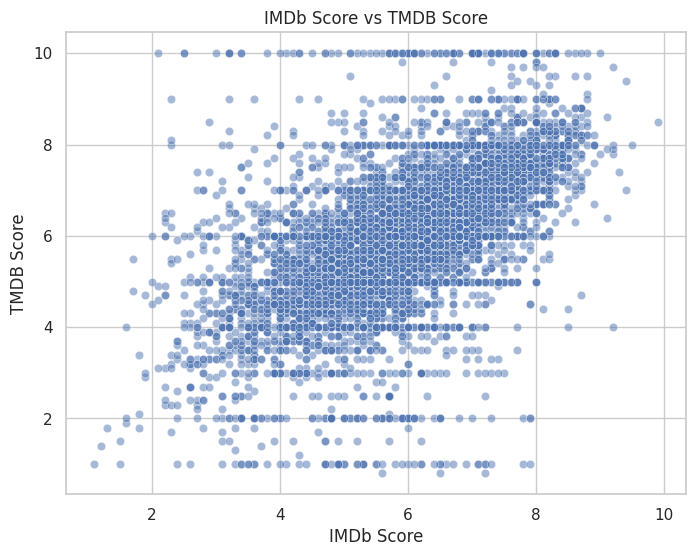

In [ ]:
rating_data = titles[["imdb_score", "tmdb_score"]].dropna()

rating_corr = rating_data["imdb_score"].corr(rating_data["tmdb_score"])

print("IMDb-TMDB correlation:", round(rating_corr, 3))

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=rating_data,
    x="imdb_score",
    y="tmdb_score",
    alpha=0.5
)
plt.title("IMDb Score vs TMDB Score")
plt.xlabel("IMDb Score")
plt.ylabel("TMDB Score")
plt.show()

### Current notebook result

IMDb-TMDB correlation ≈ **0.581**.

### Interpretation
This indicates a **moderate positive relationship**: generally, when the IMDb score increases, the TMDB score also tends to increase.

⚠️ Correlation does not mean causation.

# 17. IMDb Rating by Content Type

We will check whether there is a difference in the average IMDb rating between Movies and TV Shows.

,mean,median,count
type,,,
MOVIE,5.803110,5.9,7684
SHOW,7.118353,7.3,1166


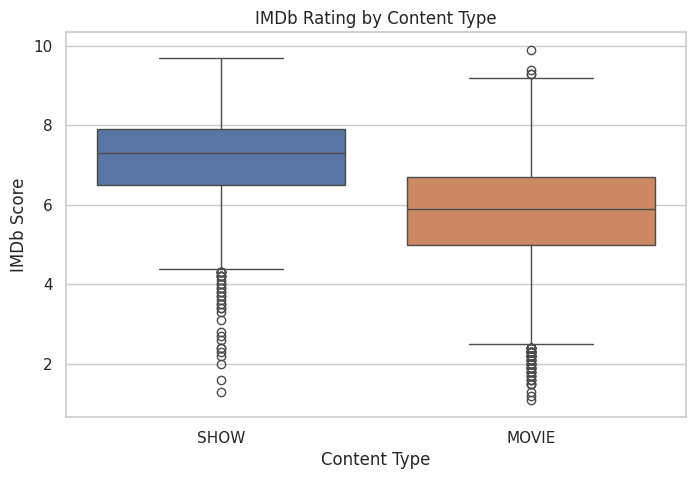

In [ ]:
rating_by_type = (
    titles.dropna(subset=["imdb_score", "type"])
    .groupby("type")["imdb_score"]
    .agg(["mean", "median", "count"])
)

display(rating_by_type)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=titles.dropna(subset=["imdb_score"]),
    x="type",
    y="imdb_score",
    hue="type",
    legend=False
)
plt.title("IMDb Rating by Content Type")
plt.xlabel("Content Type")
plt.ylabel("IMDb Score")
plt.show()

### Current notebook result

- Movies mean IMDb ≈ **5.80**
- TV Shows mean IMDb ≈ **7.12**

According to this dataset, TV Shows have a higher average IMDb score.

This is a dataset-specific observation and should not be presented as a universal rule.

# 18. Actors and Directors

`credits.csv` contains people and their roles.

We will:
- Filter ACTOR records
- Filter DIRECTOR records
- Find the most frequently credited names

**Important:** Do not call them the "most popular actors." A better term is **"most frequently credited actors."**

In [ ]:
print(credits["role"].value_counts())

actors = credits[credits["role"].eq("ACTOR")]
directors = credits[credits["role"].eq("DIRECTOR")]

top_actors = actors["name"].value_counts().head(10)
top_directors = directors["name"].value_counts().head(10)

display(top_actors.to_frame("Credits"))
display(top_directors.to_frame("Credits"))

role
ACTOR       115846
DIRECTOR      8389
Name: count, dtype: int64


,Credits
name,
George 'Gabby' Hayes,49
Roy Rogers,45
Bess Flowers,44
Gene Autry,40
Nassar,37
Charles King,36
Herman Hack,35
George Morrell,34
Forrest Taylor,34


,Credits
name,
Joseph Kane,41
Sam Newfield,38
Jay Chapman,34
Lesley Selander,22
John English,21
Harry L. Fraser,21
William Nigh,20
Manny Rodriguez,17
Robert N. Bradbury,17


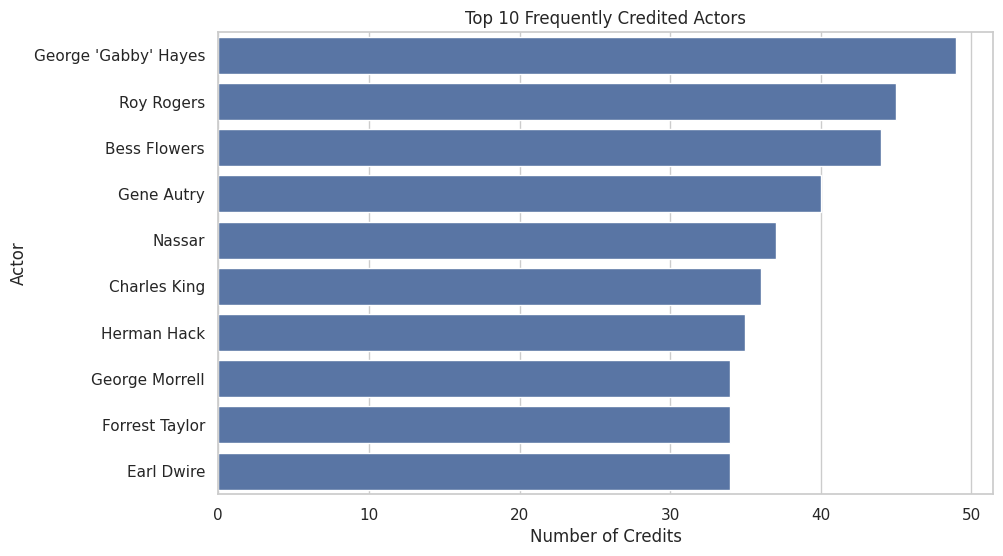

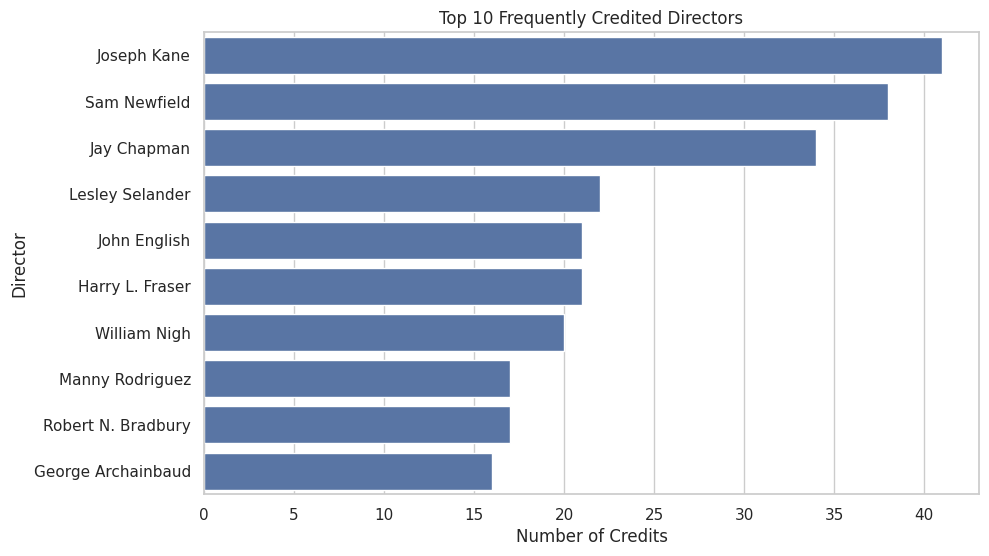

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_actors.values, y=top_actors.index)
plt.title("Top 10 Frequently Credited Actors")
plt.xlabel("Number of Credits")
plt.ylabel("Actor")
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(x=top_directors.values, y=top_directors.index)
plt.title("Top 10 Frequently Credited Directors")
plt.xlabel("Number of Credits")
plt.ylabel("Director")
plt.show()

### Current notebook result

Examples of frequently credited actors included:

- George 'Gabby' Hayes → 49
- Roy Rogers → 45
- Bess Flowers → 44

Frequently credited directors included:

- Joseph Kane → 41
- Sam Newfield → 38
- Jay Chapman → 34

These counts show **credit frequency**, not popularity or audience preference.

# 19. Production Country Analysis

We will now examine which countries are represented in the content dataset.

A title can have multiple production countries, so we will explode the list into separate rows.

In [ ]:
country_data = titles[["id", "title", "production_countries"]].dropna(
    subset=["production_countries"]
).copy()

country_data["production_countries"] = country_data[
    "production_countries"
].apply(parse_list)

country_data = country_data.explode("production_countries")

country_data["production_countries"] = (
    country_data["production_countries"].astype(str).str.strip()
)

country_data = country_data[
    country_data["production_countries"].ne("")
]

country_count = country_data["production_countries"].value_counts()

display(country_count.head(10).to_frame("Title Count"))

,Title Count
production_countries,
US,5334
IN,1072
GB,928
nan,821
CA,530
FR,250
JP,197
AU,173
DE,172


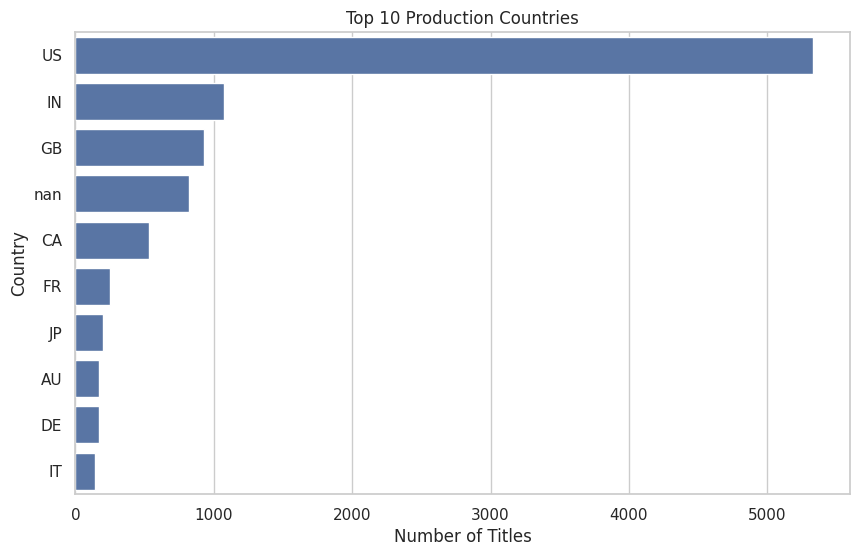

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x=country_count.head(10).values,
    y=country_count.head(10).index
)
plt.title("Top 10 Production Countries")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

### Current notebook result

Top represented countries included:

- US → **5,334**
- India → **1,072**
- GB → **928**
- Canada → **530**
- France → **250**

### Improvement
The old analysis could also include `nan` as a country representation. The new code excludes missing country entries from the valid country counts.

# 20. Runtime by Content Type

For a Movie, runtime generally represents the full movie duration, while for a TV Show it often represents episode duration.

Therefore, this limitation is important to mention when comparing the two content types.

,mean,median,min,max,count
type,,,,,
MOVIE,93.97,91.0,1,549,8514
SHOW,35.80,33.0,1,153,1357


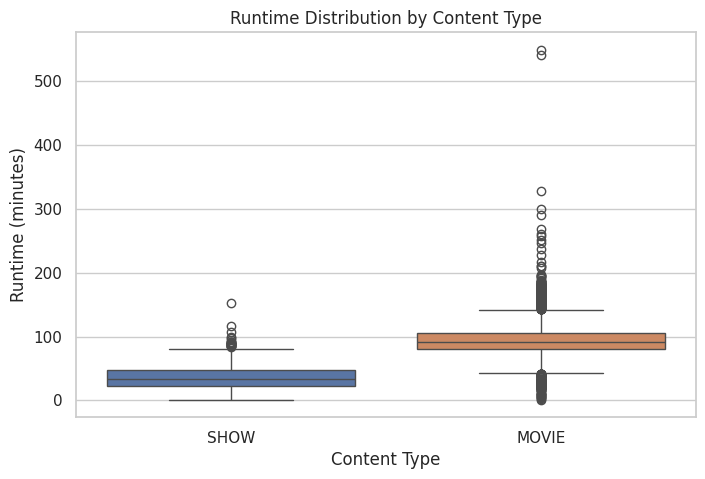

In [ ]:
runtime_data = titles.dropna(subset=["type", "runtime"])

runtime_summary = (
    runtime_data
    .groupby("type")["runtime"]
    .agg(["mean", "median", "min", "max", "count"])
    .round(2)
)

display(runtime_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=runtime_data,
    x="type",
    y="runtime",
    hue="type",
    legend=False
)
plt.title("Runtime Distribution by Content Type")
plt.xlabel("Content Type")
plt.ylabel("Runtime (minutes)")
plt.show()

### Current notebook result

- Movies mean runtime ≈ **93.97 min**
- TV Shows mean runtime ≈ **35.80 min**

Interpret the comparison carefully because Movie runtime and TV episode runtime do not represent exactly the same concept.

# 21. Age Certification

Age certification helps us understand audience classification.

We will label missing values as `Unknown` so that the chart remains easy to read.

,Title Count
age_certification,
Unknown,6487
R,1249
PG-13,588
PG,582
G,269
TV-MA,217
TV-14,188
TV-PG,91
TV-Y,78


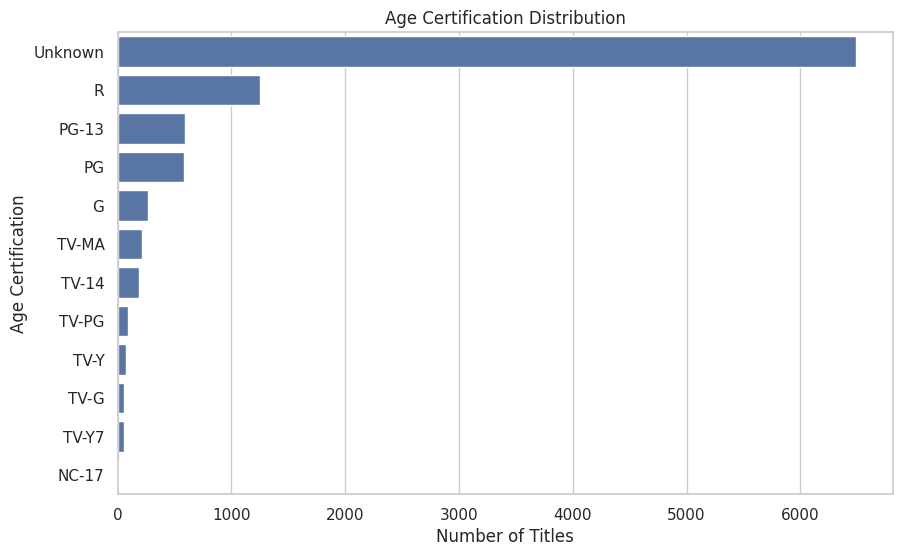

In [ ]:
certification_count = (
    titles["age_certification"]
    .fillna("Unknown")
    .value_counts()
)

display(certification_count.to_frame("Title Count"))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=certification_count.values,
    y=certification_count.index
)
plt.title("Age Certification Distribution")
plt.xlabel("Number of Titles")
plt.ylabel("Age Certification")
plt.show()

### Current notebook result

`Unknown` was the largest category because **6,487** titles were missing age-certification information.

This does not mean that 6,487 titles belong to a special age category. It only means that certification information was not available.

# 22. TMDB Popularity vs IMDb Score

We will now check how strong the relationship is between TMDB popularity and IMDb rating.

TMDB Popularity vs IMDb Score correlation: 0.072


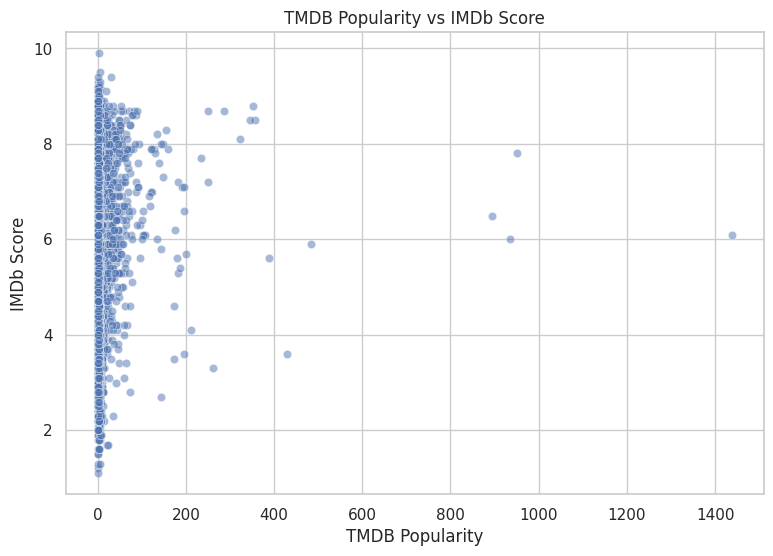

In [ ]:
popularity_data = titles[
    ["tmdb_popularity", "imdb_score"]
].dropna()

pop_corr = popularity_data["tmdb_popularity"].corr(
    popularity_data["imdb_score"]
)

print("TMDB Popularity vs IMDb Score correlation:",
      round(pop_corr, 3))

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=popularity_data,
    x="tmdb_popularity",
    y="imdb_score",
    alpha=0.5
)
plt.title("TMDB Popularity vs IMDb Score")
plt.xlabel("TMDB Popularity")
plt.ylabel("IMDb Score")
plt.show()

### Current notebook result

Correlation ≈ **0.072**, meaning the relationship is **very weakly positive**.

In simple terms, high TMDB popularity does not automatically mean a high IMDb rating.

# 23. Correlation Heatmap

We will now examine relationships between selected numerical variables in a single chart.

This allows us to compare multiple numerical relationships quickly.

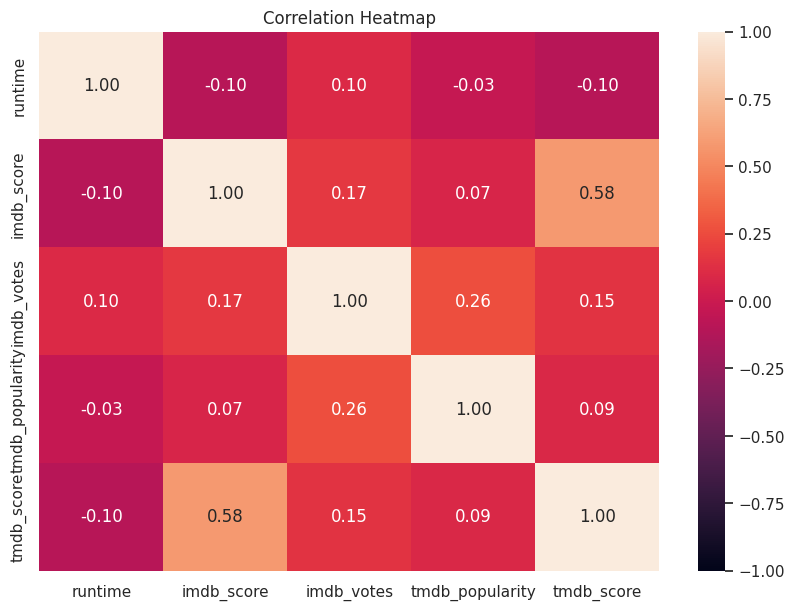

In [ ]:
selected_numeric = [
    "runtime",
    "imdb_score",
    "imdb_votes",
    "tmdb_popularity",
    "tmdb_score"
]

corr_matrix = titles[selected_numeric].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Heatmap")
plt.show()

## 24. Final KPI Summary

In a strong EDA notebook, it is useful to present the key numbers together in one place at the end.

In [ ]:
kpis = {
    "Total Titles": len(titles),
    "Movies": int((titles["type"] == "MOVIE").sum()),
    "TV Shows": int((titles["type"] == "SHOW").sum()),
    "Average IMDb Score": round(titles["imdb_score"].mean(), 2),
    "Average Movie Runtime": round(
        titles.loc[titles["type"] == "MOVIE", "runtime"].mean(), 2
    ),
    "Average TV Show Runtime": round(
        titles.loc[titles["type"] == "SHOW", "runtime"].mean(), 2
    ),
    "IMDb-TMDB Correlation": round(rating_corr, 3),
    "Runtime Potential Outliers": len(runtime_outliers)
}

display(pd.DataFrame(
    {"Metric": kpis.keys(), "Value": kpis.values()}
))

,Metric,Value
0,Total Titles,9871.000
1,Movies,8514.000
2,TV Shows,1357.000
3,Average IMDb Score,5.980
4,Average Movie Runtime,93.970
5,Average TV Show Runtime,35.800
6,IMDb-TMDB Correlation,0.581
7,Runtime Potential Outliers,275.000


### Current notebook KPI values

- Total Titles → **9,871**
- Movies → **8,514**
- TV Shows → **1,357**
- Average IMDb → **5.98**
- Average Movie Runtime → **93.97 min**
- Average TV Show Runtime → **35.80 min**
- IMDb-TMDB Correlation → **0.581**
- Runtime Potential Outliers → **275**

# 25. Final Business Findings

### Finding 1 — Content Mix
Movies represent approximately **86.25%** of the dataset, while TV Shows represent **13.75%**.

### Finding 2 — Genre
Drama was the most frequently occurring genre (**4,764**), followed by Comedy (**2,987**) and Thriller (**2,119**).

### Finding 3 — Release Trend
Among the recent-year observations in the notebook, 2021 had **856 titles**. The 2022 count was low, so recent-year data completeness should be considered.

### Finding 4 — Ratings
The correlation between IMDb and TMDB scores was approximately **0.581**, suggesting a moderate positive relationship.

### Finding 5 — Content Type Ratings
TV Shows had an average IMDb score of approximately **7.12**, compared with approximately **5.80** for Movies.

### Finding 6 — Countries
The US was the most strongly represented production country in the dataset (**5,334 titles**), followed by India (**1,072**).

### Finding 7 — Runtime
Movies had an average runtime of approximately **93.97 minutes**, while TV Shows had approximately **35.80 minutes**. The episode-duration limitation should be mentioned when interpreting TV runtime.

### Finding 8 — Popularity vs Rating
The correlation between TMDB popularity and IMDb score was only **0.072**, indicating a very weak relationship.

# 26. Final Conclusion

In this project, we performed Exploratory Data Analysis on the Amazon Prime Movies and TV Shows dataset.

We covered:
- Data loading and inspection
- Missing-value analysis
- Duplicate checks
- Data-type cleaning
- Outlier analysis
- Movies vs TV Shows distribution
- Genre analysis
- Release-year trends
- IMDb/TMDB rating analysis
- Actor/Director credit analysis
- Production-country analysis
- Runtime analysis
- Age-certification analysis
- Correlation analysis

### Main business takeaway

The dataset is strongly movie-heavy, Drama is a frequently occurring genre, IMDb and TMDB ratings have a moderate positive relationship, and TV Shows have a higher average IMDb score than Movies.

### Important limitations

- The dataset does not provide views/watch-time, so actual audience popularity cannot be measured.
- Counts for recent years such as 2022 may be incomplete.
- Missing certifications and ratings should not be filled without considering the context.
- Credits data is one-to-many; therefore, an increase in rows after merging is expected.